# GPU K-Means — Reduction V3 Aligned

This notebook preserves the team's **reduction-based centroid recomputation**
while aligning the experiment protocol with Atomic V3.

It uses:

- the exact Atomic-V3 canonical initial centroids,
- the same assignment kernel and assignment-change metric,
- the same convergence rules,
- the same empty-cluster policy,
- JIT warm-up excluded from timing,
- the same result/summary schema.

Only the centroid accumulation strategy changes:

```text
Atomic V3:
point threads -> global atomicAdd sums/counts

Reduction V3:
(K,D) reduction blocks -> centroid sums
K reduction blocks     -> cluster counts
```

Canonical starts are read from:

```text
MyDrive/kmeans_data/results_gpu_atomic_v3/
```


In [1]:
import os
import re
import math
import time
import json
import platform
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import numba
from numba import cuda



## Google Drive dataset layout

Expected structure:

```text
My Drive/
└── kmeans_data/
    ├── rows10000/
    ├── rows50000/
    ├── rows100000/
    ├── rows1000000/
    ├── rows5000000/
    └── rows10000000/
```

Files are expected to follow this naming pattern:

```text
synthetic_data_<rows>_rows_<cols>_cols_<clusters>_clusters.csv
```

Example:

```text
synthetic_data_10000_rows_10_cols_3_clusters.csv
```

The notebook parses the row count, CSV column count, and cluster count automatically.

`ID` is preserved separately and excluded from the K-Means feature matrix.


In [2]:

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

if IN_COLAB:
    DATA_ROOT = Path("/content/drive/MyDrive/kmeans_data")
else:
    DATA_ROOT = Path("./kmeans_data")

OUT_DIR = DATA_ROOT / "results_gpu_reduction_v3_aligned"
ASSIGNMENTS_DIR = OUT_DIR / "assignments"
CENTROIDS_DIR = OUT_DIR / "centroids"
HISTORY_DIR = OUT_DIR / "history"

OUT_DIR.mkdir(parents=True, exist_ok=True)
ASSIGNMENTS_DIR.mkdir(parents=True, exist_ok=True)
CENTROIDS_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------
# RUN MODE
# -----------------------------------------------------------------
# "all"        -> final full benchmark across all discovered datasets
# "diagnostic" -> only the four representative diagnostic datasets
# "single"     -> one TARGET_ROWS / TARGET_CLUSTERS dataset
RUN_MODE = "all"

DIAGNOSTIC_CASES = [
    (10_000, 3),
    (1_000_000, 3),
    (5_000_000, 9),
    (10_000_000, 17),
]

TARGET_ROWS = 10_000
TARGET_CLUSTERS = 3
TARGET_CSV_COLS = None

# Optional row-size filter in all mode.
# None = all discovered row folders.
RUN_SIZES = None

# -----------------------------------------------------------------
# CONVERGENCE
# -----------------------------------------------------------------
# Original assignment-style centroid tolerance.
TOL = 1e-4

# Practical assignment stability:
# 1e-4 = at most 0.01% of points change clusters in an iteration.
ASSIGNMENT_CHANGE_FRACTION_TOL = 1e-4

# Require the assignment-change fraction condition for multiple
# consecutive iterations to avoid stopping on a transient dip.
ASSIGNMENT_STABLE_ITERS = 3

MAX_ITER = 400
SEED = 42

# -----------------------------------------------------------------
# RESUME / OUTPUT
# -----------------------------------------------------------------
SKIP_COMPLETED = True
CONTINUE_ON_ERROR = True

SAVE_ASSIGNMENTS = True
SAVE_INITIAL_CENTROIDS = True
SAVE_FINAL_CENTROIDS = True
SAVE_ITERATION_HISTORY = True

# Optional common initial-centroid source for CPU / Atomic / Reduction.
# Set this for the final fair comparison if a shared reference folder exists.
REFERENCE_INITIAL_CENTROIDS_DIR = DATA_ROOT / "results_gpu_atomic_v3"

# For a fair comparison, Reduction must not silently invent a different start.
REQUIRE_REFERENCE_INITIAL_CENTROIDS = True

print("DATA_ROOT:", DATA_ROOT)
print("OUT_DIR  :", OUT_DIR)
print("RUN_MODE :", RUN_MODE)
print(
    "Assignment change tolerance:",
    ASSIGNMENT_CHANGE_FRACTION_TOL,
    f"({ASSIGNMENT_CHANGE_FRACTION_TOL * 100:.4f}%)"
)

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Could not find dataset folder: {DATA_ROOT}"
    )


Mounted at /content/drive
DATA_ROOT: /content/drive/MyDrive/kmeans_data
OUT_DIR  : /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned
RUN_MODE : all
Assignment change tolerance: 0.0001 (0.0100%)


In [3]:

DATASET_PATTERN = re.compile(
    r"^synthetic_data_(\d+)_rows_(\d+)_cols_(\d+)_clusters\.csv$"
)

ROW_FOLDER_PATTERN = re.compile(r"^rows(\d+)$")


def discover_datasets(data_root):
    """
    Scan folders named exactly rows<number>, e.g.
      rows10000
      rows50000
      rows100000
      rows1000000
      rows5000000
      rows10000000

    and discover CSVs named:
      synthetic_data_<rows>_rows_<cols>_cols_<clusters>_clusters.csv
    """
    records = []

    for folder in sorted(data_root.iterdir()):
        if not folder.is_dir():
            continue

        folder_match = ROW_FOLDER_PATTERN.match(folder.name)
        if folder_match is None:
            continue

        folder_rows = int(folder_match.group(1))

        for csv_path in sorted(folder.glob("*.csv")):
            match = DATASET_PATTERN.match(csv_path.name)

            if match is None:
                continue

            filename_rows = int(match.group(1))
            csv_cols = int(match.group(2))
            clusters = int(match.group(3))

            records.append({
                "rows": filename_rows,
                "csv_cols": csv_cols,
                "clusters": clusters,
                "folder": folder.name,
                "folder_rows": folder_rows,
                "filename": csv_path.name,
                "path": str(csv_path),
                "folder_matches_filename_rows": (
                    folder_rows == filename_rows
                ),
            })

    if not records:
        raise FileNotFoundError(
            f"No matching datasets found under rows<number> folders in {data_root}"
        )

    catalog = (
        pd.DataFrame(records)
        .sort_values(["rows", "clusters", "csv_cols"])
        .reset_index(drop=True)
    )

    mismatches = catalog[
        ~catalog["folder_matches_filename_rows"]
    ]

    if len(mismatches):
        print("WARNING: folder/filename row-count mismatches:")
        display(
            mismatches[
                ["folder", "filename", "folder_rows", "rows"]
            ]
        )

    return catalog


dataset_catalog = discover_datasets(DATA_ROOT)

print(
    f"Discovered {len(dataset_catalog)} dataset files "
    f"across {dataset_catalog['folder'].nunique()} row folders."
)

display(
    dataset_catalog[
        ["folder", "rows", "csv_cols", "clusters", "filename"]
    ]
)


Discovered 18 dataset files across 6 row folders.


,folder,rows,csv_cols,clusters,filename
0,rows10000,10000,10,3,synthetic_data_10000_rows_10_cols_3_clusters.csv
1,rows10000,10000,10,5,synthetic_data_10000_rows_10_cols_5_clusters.csv
2,rows10000,10000,10,7,synthetic_data_10000_rows_10_cols_7_clusters.csv
3,rows50000,50000,10,7,synthetic_data_50000_rows_10_cols_7_clusters.csv
4,rows50000,50000,10,9,synthetic_data_50000_rows_10_cols_9_clusters.csv
5,rows50000,50000,10,11,synthetic_data_50000_rows_10_cols_11_clusters.csv
6,rows100000,100000,10,13,synthetic_data_100000_rows_10_cols_13_clusters...
7,rows100000,100000,10,15,synthetic_data_100000_rows_10_cols_15_clusters...
8,rows100000,100000,10,17,synthetic_data_100000_rows_10_cols_17_clusters...
9,rows1000000,1000000,10,3,synthetic_data_1000000_rows_10_cols_3_clusters...


## Final run mode

The notebook defaults to:

```python
RUN_MODE = "all"
```

so it runs every matching synthetic dataset discovered under the `rows<number>` folders.

The final assignment-stability threshold is:

```python
ASSIGNMENT_CHANGE_FRACTION_TOL = 1e-4
ASSIGNMENT_STABLE_ITERS = 3
```

That means the clustering may stop after **three consecutive iterations in which no more than 0.01% of points change cluster**, or earlier if the centroid-movement tolerance is met.

This criterion is size-normalized, so it can be applied consistently to 10K, 1M, 5M, and 10M datasets.


In [4]:

def select_dataset(
    catalog,
    target_rows,
    target_clusters,
    target_csv_cols=None
):
    matches = catalog[
        (catalog["rows"] == target_rows)
        & (catalog["clusters"] == target_clusters)
    ]

    if target_csv_cols is not None:
        matches = matches[
            matches["csv_cols"] == target_csv_cols
        ]

    if len(matches) == 0:
        raise ValueError(
            "No dataset matched the requested configuration.\n\n"
            + catalog[
                ["folder", "rows", "csv_cols", "clusters", "filename"]
            ].to_string(index=False)
        )

    if len(matches) > 1:
        raise ValueError(
            "More than one dataset matched. "
            "Set TARGET_CSV_COLS to disambiguate.\n\n"
            + matches.to_string(index=False)
        )

    return matches.iloc[0]


selected = None
DATASET_PATH = None

if RUN_MODE == "single":
    selected = select_dataset(
        dataset_catalog,
        TARGET_ROWS,
        TARGET_CLUSTERS,
        TARGET_CSV_COLS
    )

    DATASET_PATH = Path(selected["path"])

    print("Selected:", DATASET_PATH)
else:
    print(
        "Batch mode enabled: every matching CSV inside every "
        "rows<number> folder will be processed."
    )


Batch mode enabled: every matching CSV inside every rows<number> folder will be processed.


In [5]:

LABEL_NAMES = {
    "true_label", "label", "labels",
    "cluster", "clusters", "cluster_id",
    "target", "class", "y"
}

ID_NAMES = {"id", "index", "idx", "row", "row_id"}


def load_dataset_for_kmeans(path, selected_meta):
    df = pd.read_csv(path)

    id_candidates = [
        c for c in df.columns
        if str(c).strip().lower() in ID_NAMES
    ]
    id_col = id_candidates[0] if id_candidates else None

    if id_col is not None:
        ids = df[id_col].astype(str).to_numpy()
    else:
        ids = np.arange(len(df)).astype(str)

    label_candidates = [
        c for c in df.columns
        if str(c).strip().lower() in LABEL_NAMES
    ]
    label_col = label_candidates[0] if label_candidates else None

    true_label = (
        df[label_col].to_numpy()
        if label_col is not None
        else None
    )

    excluded = {id_col, label_col}

    feature_cols = [
        c for c in df.columns
        if c not in excluded
        and pd.api.types.is_numeric_dtype(df[c])
    ]

    if not feature_cols:
        raise ValueError(
            f"No numeric feature columns found in {path.name}"
        )

    df_data = df[feature_cols]

    N = len(df_data)
    D = len(feature_cols)
    K = int(selected_meta["clusters"])

    print("\nDataset verification")
    print("--------------------")
    print("File                     :", path.name)
    print("Actual rows              :", N)
    print("Actual total CSV columns :", len(df.columns))
    print("ID column                :", id_col)
    print("Label column excluded    :", label_col)
    print("K-Means feature count D  :", D)
    print("Cluster count K          :", K)
    print("Feature columns          :", feature_cols)

    if N != int(selected_meta["rows"]):
        print("WARNING: actual row count differs from filename metadata.")

    if len(df.columns) != int(selected_meta["csv_cols"]):
        print(
            "NOTE: actual CSV column count differs from filename metadata. "
            "A generated label column may explain the difference."
        )

    return (
        df,
        ids,
        df_data,
        true_label,
        feature_cols,
        N,
        D,
        K,
        id_col,
        label_col,
    )


if RUN_MODE == "single":
    (
        df,
        ids,
        df_data,
        true_label,
        d_dims,
        N1,
        D1,
        K1,
        ID_COLUMN_FOUND,
        LABEL_COLUMN_FOUND,
    ) = load_dataset_for_kmeans(
        DATASET_PATH,
        selected
    )

    display(df_data.head())


In [6]:

@cuda.jit
def calculate_clusters(
    data,
    centroids,
    assign,
    changed_count
):
    """
    One CUDA thread processes one point and assigns it to the nearest centroid.

    This V2 kernel also counts how many assignments changed.

    To avoid a highly contended global atomic for every changed point:
      1. each thread writes 0/1 into shared memory,
      2. the block reduces those flags,
      3. only thread 0 performs ONE atomicAdd per block.

    This change-count mechanism should be reused by the reduction version
    later so Atomic-vs-Reduction timing remains fair.
    """

    i = cuda.grid(1)

    row = data.shape[0]
    dim = data.shape[1]
    clusters = centroids.shape[0]

    th_id = cuda.threadIdx.x
    block_size = cuda.blockDim.x

    # Shared centroid cache.
    shared_centroids = cuda.shared.array(
        shape=(max_k, max_d),
        dtype=np.float64
    )

    # One change flag per thread.
    # This notebook uses THREADS_PER_BLOCK = 256.
    shared_changed = cuda.shared.array(
        shape=256,
        dtype=np.int32
    )

    # ------------------------------------------------------------
    # Cooperative centroid loading
    # ------------------------------------------------------------
    idx = th_id
    total = clusters * dim

    while idx < total:
        k = idx // dim
        j = idx % dim
        shared_centroids[k, j] = centroids[k, j]
        idx += block_size

    cuda.syncthreads()

    # ------------------------------------------------------------
    # Point assignment
    # ------------------------------------------------------------
    local_changed = 0

    if i < row:
        best_cluster = 0
        best_distance = math.inf

        for k in range(clusters):
            distance = 0.0

            for j in range(dim):
                diff = data[i, j] - shared_centroids[k, j]
                distance += diff * diff

            if distance < best_distance:
                best_distance = distance
                best_cluster = k

        old_cluster = assign[i]

        if old_cluster != best_cluster:
            local_changed = 1

        assign[i] = best_cluster

    # ------------------------------------------------------------
    # Block-level reduction of assignment-change flags
    # ------------------------------------------------------------
    shared_changed[th_id] = local_changed
    cuda.syncthreads()

    stride = block_size // 2

    while stride > 0:
        if th_id < stride:
            shared_changed[th_id] += shared_changed[th_id + stride]

        cuda.syncthreads()
        stride //= 2

    # Only one global atomic per block.
    if th_id == 0 and shared_changed[0] > 0:
        cuda.atomic.add(
            changed_count,
            0,
            shared_changed[0]
        )


In [7]:

@cuda.jit
def cal_centroid_sums(
    data,
    assignments,
    centroid_sums
):
    """
    Reduction approach from the team notebook.

    Each block owns one (cluster k, dimension j) pair.
    Threads scan the rows in strides, accumulate a local sum,
    then reduce through shared memory.
    """
    th_id = cuda.threadIdx.x
    block_id = cuda.blockIdx.x
    block_size = cuda.blockDim.x

    N = data.shape[0]
    D = data.shape[1]

    k = block_id // D
    j = block_id % D

    if k >= centroid_sums.shape[0]:
        return

    shared_sum = cuda.shared.array(
        shape=256,
        dtype=np.float64
    )

    local_sum = 0.0
    i = th_id

    while i < N:
        if assignments[i] == k:
            local_sum += data[i, j]
        i += block_size

    shared_sum[th_id] = local_sum
    cuda.syncthreads()

    stride = block_size // 2

    while stride > 0:
        if th_id < stride:
            shared_sum[th_id] += shared_sum[th_id + stride]

        cuda.syncthreads()
        stride //= 2

    if th_id == 0:
        centroid_sums[k, j] = shared_sum[0]


@cuda.jit
def cal_cluster_count(
    assignments,
    cluster_counts
):
    """
    One reduction block per cluster.
    """
    th_id = cuda.threadIdx.x
    block_id = cuda.blockIdx.x
    block_size = cuda.blockDim.x

    N = assignments.shape[0]
    K = cluster_counts.shape[0]

    if block_id >= K:
        return

    shared_count = cuda.shared.array(
        shape=256,
        dtype=np.int32
    )

    local_count = 0
    i = th_id

    while i < N:
        if assignments[i] == block_id:
            local_count += 1
        i += block_size

    shared_count[th_id] = local_count
    cuda.syncthreads()

    stride = block_size // 2

    while stride > 0:
        if th_id < stride:
            shared_count[th_id] += shared_count[th_id + stride]

        cuda.syncthreads()
        stride //= 2

    if th_id == 0:
        cluster_counts[block_id] = shared_count[0]


## Reduction version: centroid sums and counts use shared-memory reductions

The assignment kernel is intentionally the same as Atomic V3.  
The difference under test is the centroid-recomputation strategy.


In [8]:
@cuda.jit
def update_centroids(centroid_sums, cluster_counts, centroids):
    '''updated centroid with mean'''

    block_id = cuda.blockIdx.x
    th_id = cuda.threadIdx.x

    K = centroids.shape[0]
    D = centroids.shape[1]


    if block_id >= K or th_id >= D:
        return

    count = cluster_counts[block_id]

    if count > 0:
        # avg
        centroids[block_id, th_id] = (centroid_sums[block_id, th_id] / count)

In [9]:
import time
import pandas as pd

# df = pd.read_csv("./rows10000/synthetic_data_10000_rows_11_cols_3_clusters.csv")
# df.head()

In [10]:

def run_kmeans_reduction(
    df_data,
    K,
    max_iter=MAX_ITER,
    tol=TOL,
    assignment_fraction_tol=ASSIGNMENT_CHANGE_FRACTION_TOL,
    assignment_stable_iters=ASSIGNMENT_STABLE_ITERS,
    initial_indices=None,
    initial_centroids=None,
    seed=SEED,
    verbose=True
):
    """
    Reduction-based GPU K-Means using the same convergence/timing protocol
    as Atomic V3.
    """
    h_data = np.ascontiguousarray(
        df_data.to_numpy(dtype=np.float64)
    )

    N, D = h_data.shape

    if K > max_k:
        raise ValueError(f"K={K} exceeds max_k={max_k}")

    if D > max_d:
        raise ValueError(f"D={D} exceeds max_d={max_d}")

    if verbose:
        print(
            f"--- Running K-Means REDUCTION V3 "
            f"(N={N}, D={D}, K={K}) ---"
        )

    # ------------------------------------------------------------
    # Initial centroids
    # ------------------------------------------------------------
    if initial_centroids is not None:
        h_centroids = np.ascontiguousarray(
            np.asarray(initial_centroids, dtype=np.float64)
        )

        if h_centroids.shape != (K, D):
            raise ValueError(
                f"initial_centroids shape {h_centroids.shape} "
                f"does not match expected {(K, D)}"
            )

        initial_indices_used = None
    else:
        if initial_indices is None:
            rng = np.random.default_rng(seed)
            initial_indices = rng.choice(
                N,
                K,
                replace=False
            )

        initial_indices = np.asarray(
            initial_indices,
            dtype=np.int64
        )

        h_centroids = h_data[initial_indices].copy()
        initial_indices_used = initial_indices.copy()

    initial_centroids_used = h_centroids.copy()
    h_assign = np.full(N, -1, dtype=np.int32)

    # Actual run buffers.
    d_data = cuda.to_device(h_data)
    d_centroids = cuda.to_device(h_centroids)
    d_assign = cuda.to_device(h_assign)

    blocks_per_grid_points = math.ceil(
        N / THREADS_PER_BLOCK
    )

    h_zero_changed = np.zeros(1, dtype=np.int32)
    d_changed_count = cuda.to_device(h_zero_changed)

    # ------------------------------------------------------------
    # JIT warm-up on a SMALL slice -- excluded from timing.
    # This avoids making the reduction warm-up scan the entire 10M file.
    # ------------------------------------------------------------
    warm_n = min(N, 4096)

    d_warm_data = cuda.to_device(
        np.ascontiguousarray(h_data[:warm_n])
    )
    d_warm_centroids = cuda.to_device(
        initial_centroids_used.copy()
    )
    d_warm_assign = cuda.to_device(
        np.full(warm_n, -1, dtype=np.int32)
    )
    d_warm_sums = cuda.to_device(
        np.zeros((K, D), dtype=np.float64)
    )
    d_warm_counts = cuda.to_device(
        np.zeros(K, dtype=np.int32)
    )
    d_warm_changed = cuda.to_device(
        np.zeros(1, dtype=np.int32)
    )

    warm_blocks = math.ceil(
        warm_n / THREADS_PER_BLOCK
    )

    warmup_start = time.perf_counter()

    calculate_clusters[
        warm_blocks,
        THREADS_PER_BLOCK
    ](
        d_warm_data,
        d_warm_centroids,
        d_warm_assign,
        d_warm_changed
    )

    cal_centroid_sums[
        K * D,
        THREADS_PER_BLOCK
    ](
        d_warm_data,
        d_warm_assign,
        d_warm_sums
    )

    cal_cluster_count[
        K,
        THREADS_PER_BLOCK
    ](
        d_warm_assign,
        d_warm_counts
    )

    update_centroids[
        K,
        D
    ](
        d_warm_sums,
        d_warm_counts,
        d_warm_centroids
    )

    cuda.synchronize()

    warmup_time = (
        time.perf_counter() - warmup_start
    )

    if verbose:
        print(
            f"CUDA/Numba warm-up: {warmup_time:.4f} s "
            "(excluded)"
        )

    # ------------------------------------------------------------
    # Timed execution
    # ------------------------------------------------------------
    start_time = time.perf_counter()

    cent_shift = math.inf
    changed = N
    changed_fraction = 1.0

    converged = False
    convergence_reason = "max_iterations"
    stable_fraction_streak = 0
    history = []

    for iteration in range(max_iter):
        old_centroids = h_centroids.copy()

        d_centroid_sums = cuda.to_device(
            np.zeros((K, D), dtype=np.float64)
        )

        d_cluster_counts = cuda.to_device(
            np.zeros(K, dtype=np.int32)
        )

        d_changed_count.copy_to_device(
            h_zero_changed
        )

        # 1) Same assignment kernel as Atomic V3.
        calculate_clusters[
            blocks_per_grid_points,
            THREADS_PER_BLOCK
        ](
            d_data,
            d_centroids,
            d_assign,
            d_changed_count
        )

        cuda.synchronize()

        changed = int(
            d_changed_count.copy_to_host()[0]
        )

        changed_fraction = (
            changed / float(N)
        )

        # 2) Reduction-based centroid sums.
        cal_centroid_sums[
            K * D,
            THREADS_PER_BLOCK
        ](
            d_data,
            d_assign,
            d_centroid_sums
        )

        cuda.synchronize()

        # 3) Reduction-based cluster counts.
        cal_cluster_count[
            K,
            THREADS_PER_BLOCK
        ](
            d_assign,
            d_cluster_counts
        )

        cuda.synchronize()

        # 4) Centroid mean.
        update_centroids[
            K,
            D
        ](
            d_centroid_sums,
            d_cluster_counts,
            d_centroids
        )

        cuda.synchronize()

        d_centroids.copy_to_host(
            h_centroids
        )

        cent_shift = float(
            np.max(
                np.sqrt(
                    np.sum(
                        (h_centroids - old_centroids) ** 2,
                        axis=1
                    )
                )
            )
        )

        centroid_converged = (
            cent_shift < tol
        )

        assignment_fraction_met = (
            changed_fraction
            <= assignment_fraction_tol
        )

        if assignment_fraction_met:
            stable_fraction_streak += 1
        else:
            stable_fraction_streak = 0

        assignment_stability_met = (
            stable_fraction_streak
            >= assignment_stable_iters
        )

        history.append({
            "iteration": iteration + 1,
            "assignment_changes": changed,
            "assignment_change_fraction": changed_fraction,
            "assignment_change_percent": changed_fraction * 100.0,
            "max_centroid_movement": cent_shift,
            "stable_fraction_streak": stable_fraction_streak,
            "centroid_tolerance_met": centroid_converged,
            "assignment_fraction_tolerance_met": assignment_fraction_met,
            "assignment_stability_met": assignment_stability_met,
        })

        if verbose and (
            iteration < 5
            or assignment_fraction_met
            or (iteration + 1) % 25 == 0
        ):
            print(
                f"iter={iteration + 1:4d} | "
                f"changed={changed:10d} | "
                f"changed%={changed_fraction * 100:.5f}% | "
                f"shift={cent_shift:.8f} | "
                f"stable-streak={stable_fraction_streak}"
            )

        if centroid_converged or assignment_stability_met:
            converged = True

            if centroid_converged and assignment_stability_met:
                convergence_reason = "both"
            elif assignment_stability_met:
                convergence_reason = "assignment_fraction_stable"
            else:
                convergence_reason = "centroid_tolerance"

            break

    cuda.synchronize()

    exec_time = (
        time.perf_counter() - start_time
    )

    d_assign.copy_to_host(
        h_assign
    )

    if verbose:
        print(f"Timed execution      : {exec_time:.4f} s")
        print(f"Warm-up excluded     : {warmup_time:.4f} s")
        print(f"Iterations           : {iteration + 1}")
        print(f"Converged            : {converged}")
        print(f"Reason               : {convergence_reason}")
        print(f"Final changes        : {changed}")
        print(
            f"Final change fraction : "
            f"{changed_fraction:.8e}"
        )
        print(f"Final shift          : {cent_shift:.8f}")

    return {
        "assignments": h_assign,
        "centroids": h_centroids,
        "initial_centroids": initial_centroids_used,
        "initial_indices": initial_indices_used,
        "iterations": iteration + 1,
        "execution_time": float(exec_time),
        "warmup_time": float(warmup_time),
        "max_movement": cent_shift,
        "assignment_changes": int(changed),
        "assignment_change_fraction": float(changed_fraction),
        "stable_fraction_streak": int(stable_fraction_streak),
        "converged": converged,
        "convergence_reason": convergence_reason,
        "history": pd.DataFrame(history),
    }



## Output files

To match the CPU baseline as closely as practical, each GPU run writes:

```text
results_gpu_atomic/
├── environment.json
├── summary.csv
├── initial_centroids_<dataset-tag>.csv
├── final_results_<dataset-tag>.csv
├── assignments/
│   └── assignments_<dataset-tag>.csv
└── centroids/
    └── final_centroids_<dataset-tag>.csv
```

The assignment file contains:

```text
ID, cluster, distance
```

and includes `true_label` as an extra reference column when the source CSV provides it. The label is **never** used as a clustering feature.


In [11]:

max_k = 64
max_d = 32
THREADS_PER_BLOCK = 256

try:
    device = cuda.get_current_device()
    gpu_name = device.name

    if isinstance(gpu_name, bytes):
        gpu_name = gpu_name.decode()

    compute_capability = ".".join(
        map(str, device.compute_capability)
    )
except Exception:
    gpu_name = "unknown"
    compute_capability = "unknown"

ENV = {
    "implementation": "gpu_reduction_numba_cuda_v3_aligned",
    "gpu_name": gpu_name,
    "compute_capability": compute_capability,
    "platform": platform.platform(),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "numba": numba.__version__,
    "threads_per_block": THREADS_PER_BLOCK,
    "max_k": max_k,
    "max_d": max_d,
    "centroid_tolerance": TOL,
    "assignment_change_fraction_tolerance":
        ASSIGNMENT_CHANGE_FRACTION_TOL,
    "assignment_stable_iterations":
        ASSIGNMENT_STABLE_ITERS,
    "max_iterations": MAX_ITER,
    "seed": SEED,
    "jit_warmup_excluded_from_timing": True,
    "canonical_initial_centroids_dir": str(REFERENCE_INITIAL_CENTROIDS_DIR),
    "data_root": str(DATA_ROOT),
}

with open(
    OUT_DIR / "environment.json",
    "w"
) as fh:
    json.dump(
        ENV,
        fh,
        indent=2
    )

ENV


{'implementation': 'gpu_reduction_numba_cuda_v3_aligned',
 'gpu_name': 'Tesla T4',
 'compute_capability': '7.5',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'python': '3.13.15',
 'numpy': '2.1.3',
 'pandas': '2.2.3',
 'numba': '0.61.2',
 'threads_per_block': 256,
 'max_k': 64,
 'max_d': 32,
 'centroid_tolerance': 0.0001,
 'assignment_change_fraction_tolerance': 0.0001,
 'assignment_stable_iterations': 3,
 'max_iterations': 400,
 'seed': 42,
 'jit_warmup_excluded_from_timing': True,
 'canonical_initial_centroids_dir': '/content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3',
 'data_root': '/content/drive/MyDrive/kmeans_data'}


## Output helpers

Distances are calculated **after convergence** against each point's assigned final centroid.

For very large datasets this is done in chunks so we do not create a full `N × D` temporary matrix at once.


In [12]:

def dataset_tag_from_path(path):
    return Path(path).stem


def calculate_assigned_distances(
    X,
    centroids,
    assignments,
    chunk_size=500_000
):
    """
    Distance from each point to its assigned final centroid.
    Chunked to control host-memory use for multi-million-row data.
    """
    X = np.asarray(X, dtype=np.float64)
    assignments = np.asarray(assignments, dtype=np.int32)

    distances = np.empty(len(X), dtype=np.float64)

    for start in range(0, len(X), chunk_size):
        end = min(start + chunk_size, len(X))

        a = assignments[start:end]
        diff = X[start:end] - centroids[a]

        distances[start:end] = np.sqrt(
            np.sum(diff * diff, axis=1)
        )

    return distances


def calculate_wcss_from_distances(distances):
    return float(
        np.sum(
            np.asarray(distances, dtype=np.float64) ** 2
        )
    )


def initial_centroid_sha256(C):
    arr = np.ascontiguousarray(
        np.asarray(C, dtype=np.float64)
    )
    return hashlib.sha256(arr.tobytes()).hexdigest()


def _read_initial_centroid_csv(path, K, D, feature_cols=None):
    """
    Read the canonical Atomic-V3 centroid file.

    The saved format is:
        cluster,col_1,...,col_D

    The 'cluster' metadata column is explicitly excluded.
    """
    df = pd.read_csv(path)

    if "cluster" in df.columns:
        df = df.drop(columns=["cluster"])

    if feature_cols is not None and all(c in df.columns for c in feature_cols):
        df = df[list(feature_cols)]
    else:
        df = df.select_dtypes(include=[np.number])

    arr = df.to_numpy(dtype=np.float64)

    if arr.shape != (K, D):
        raise ValueError(
            f"{path} has centroid shape {arr.shape}; expected {(K, D)}"
        )

    return np.ascontiguousarray(arr, dtype=np.float64)


def find_reference_initial_centroids(tag, K, D, feature_cols=None):
    """
    Reuse canonical initial_centroids_<tag>.csv when available.

    Atomic may create the file on the first run. CPU and Reduction use
    their aligned notebooks with REQUIRE_REFERENCE_INITIAL_CENTROIDS=True.
    """
    if REFERENCE_INITIAL_CENTROIDS_DIR is None:
        return None

    ref_dir = Path(REFERENCE_INITIAL_CENTROIDS_DIR)
    path = ref_dir / f"initial_centroids_{tag}.csv"

    if not path.exists():
        if REQUIRE_REFERENCE_INITIAL_CENTROIDS:
            raise FileNotFoundError(
                f"Canonical initial-centroid file not found: {path}"
            )
        print(
            "Canonical initial-centroid file does not exist yet; "
            "Atomic will create it deterministically:",
            path
        )
        return None

    arr = _read_initial_centroid_csv(
        path,
        K,
        D,
        feature_cols=feature_cols
    )

    print("Using canonical initial centroids:", path)
    print("Initial centroid SHA256:", initial_centroid_sha256(arr))

    return arr


def save_run_outputs(
    path,
    meta,
    ids,
    feature_cols,
    true_label,
    X,
    result
):
    tag = dataset_tag_from_path(path)

    assignments = result["assignments"]
    centroids = result["centroids"]

    # ------------------------------------------------------------
    # Distances + WCSS
    # ------------------------------------------------------------
    distances = calculate_assigned_distances(
        X,
        centroids,
        assignments
    )

    wcss = calculate_wcss_from_distances(distances)

    cluster_sizes = np.bincount(
        assignments,
        minlength=len(centroids)
    )

    # ------------------------------------------------------------
    # Initial centroids
    # ------------------------------------------------------------
    if SAVE_INITIAL_CENTROIDS:
        init_df = pd.DataFrame(
            result["initial_centroids"],
            columns=feature_cols
        )
        init_df.insert(
            0,
            "cluster",
            np.arange(len(init_df))
        )
        init_df.to_csv(
            OUT_DIR / f"initial_centroids_{tag}.csv",
            index=False
        )

    # ------------------------------------------------------------
    # Final centroid table
    # ------------------------------------------------------------
    if SAVE_FINAL_CENTROIDS:
        cent_df = pd.DataFrame(
            centroids,
            columns=feature_cols
        )
        cent_df.insert(
            0,
            "cluster",
            np.arange(len(cent_df))
        )
        cent_df["cluster_size"] = cluster_sizes

        cent_df.to_csv(
            CENTROIDS_DIR / f"final_centroids_{tag}.csv",
            index=False
        )

    # ------------------------------------------------------------
    # Per-ID assignments
    # ------------------------------------------------------------
    assignment_path = ASSIGNMENTS_DIR / f"assignments_{tag}.csv"

    if SAVE_ASSIGNMENTS:
        out = pd.DataFrame({
            "ID": ids,
            "cluster": assignments,
            "distance": distances,
        })

        if true_label is not None:
            out["true_label"] = true_label

        out.to_csv(
            assignment_path,
            index=False
        )

    # ------------------------------------------------------------
    # One-row final result
    # ------------------------------------------------------------
    # ------------------------------------------------------------
    # Iteration history
    # ------------------------------------------------------------
    if SAVE_ITERATION_HISTORY:
        result["history"].to_csv(
            HISTORY_DIR / f"history_{tag}.csv",
            index=False
        )

    # ------------------------------------------------------------
    # One-row final result
    # ------------------------------------------------------------
    final_row = {
        "Implementation": "gpu_reduction_v3_aligned",
        "Initial centroid source": str(REFERENCE_INITIAL_CENTROIDS_DIR),
        "Initial centroid SHA256": initial_centroid_sha256(result["initial_centroids"]),
        "Dataset": tag,
        "Rows": len(X),
        "Features": X.shape[1],
        "K": len(centroids),
        "Execution time": result["execution_time"],
        "Warmup time": result["warmup_time"],
        "Warmup excluded": True,
        "Iterations": result["iterations"],
        "Per iteration ms": (
            result["execution_time"]
            / result["iterations"]
            * 1000.0
        ),
        "Converged": result["converged"],
        "Convergence reason": result["convergence_reason"],
        "Final assignment changes":
            result["assignment_changes"],
        "Final assignment change fraction":
            result["assignment_change_fraction"],
        "Final assignment change percent":
            result["assignment_change_fraction"] * 100.0,
        "Stable fraction streak":
            result["stable_fraction_streak"],
        "Max movement": result["max_movement"],
        "WCSS": wcss,
        "Cluster sizes": json.dumps(
            cluster_sizes.tolist()
        ),
        "Centroids": json.dumps(
            centroids.astype(float).tolist()
        ),
    }

    pd.DataFrame([final_row]).to_csv(
        OUT_DIR / f"final_results_{tag}.csv",
        index=False
    )

    return final_row, assignment_path



## Run / resume batch

With `RUN_MODE = "all"` the notebook now runs **every matching CSV** inside every folder named `rows<number>`.

`summary.csv` is saved **after every successful dataset**, so progress survives a Colab disconnect.


In [13]:

SUMMARY_PATH = OUT_DIR / "summary.csv"


def update_summary_csv(new_rows):
    valid_rows = [
        row for row in new_rows
        if row is not None
    ]

    new_df = pd.DataFrame(
        valid_rows
    )

    if SUMMARY_PATH.exists():
        old_df = pd.read_csv(
            SUMMARY_PATH
        )

        if len(new_df):
            combined = pd.concat(
                [old_df, new_df],
                ignore_index=True
            )
        else:
            combined = old_df
    else:
        combined = new_df

    if len(combined):
        combined = combined.drop_duplicates(
            subset=[
                "Dataset",
                "Implementation"
            ],
            keep="last"
        )

        combined = combined.sort_values(
            [
                "Rows",
                "K",
                "Implementation"
            ]
        ).reset_index(drop=True)

    combined.to_csv(
        SUMMARY_PATH,
        index=False
    )

    return combined


def final_result_path_for(path):
    tag = dataset_tag_from_path(
        path
    )

    return (
        OUT_DIR
        / f"final_results_{tag}.csv"
    )


def run_one_dataset(path, meta):
    final_path = final_result_path_for(
        path
    )

    if SKIP_COMPLETED and final_path.exists():
        print(
            "SKIP (already completed):",
            path.name
        )

        return (
            pd.read_csv(final_path)
            .iloc[0]
            .to_dict()
        )

    (
        df_full,
        ids_local,
        df_features,
        true_label_local,
        feature_cols,
        N,
        D,
        K,
        id_col,
        label_col,
    ) = load_dataset_for_kmeans(
        path,
        meta
    )

    if K > max_k:
        raise ValueError(
            f"K={K} exceeds max_k={max_k}"
        )

    if D > max_d:
        raise ValueError(
            f"D={D} exceeds max_d={max_d}"
        )

    tag = dataset_tag_from_path(
        path
    )

    reference_C0 = (
        find_reference_initial_centroids(
            tag,
            K,
            D,
            feature_cols=feature_cols
        )
    )

    result = run_kmeans_reduction(
        df_data=df_features,
        K=K,
        max_iter=MAX_ITER,
        tol=TOL,
        seed=SEED,
        initial_centroids=reference_C0,
        verbose=True
    )

    final_row, assignment_path = (
        save_run_outputs(
            path=path,
            meta=meta,
            ids=ids_local,
            feature_cols=feature_cols,
            true_label=true_label_local,
            X=df_features.to_numpy(
                dtype=np.float64
            ),
            result=result
        )
    )

    print(
        "Saved final result:",
        final_path
    )

    if SAVE_ASSIGNMENTS:
        print(
            "Saved assignments:",
            assignment_path
        )

    if SAVE_ITERATION_HISTORY:
        print(
            "Saved history:",
            HISTORY_DIR
            / f"history_{tag}.csv"
        )

    return final_row


In [14]:

def select_diagnostic_catalog(
    catalog,
    cases
):
    selected_rows = []

    for rows, k in cases:
        matches = catalog[
            (catalog["rows"] == rows)
            & (catalog["clusters"] == k)
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Expected exactly one dataset for "
                f"rows={rows}, K={k}; found {len(matches)}"
            )

        selected_rows.append(
            matches.iloc[0]
        )

    return pd.DataFrame(
        selected_rows
    ).reset_index(drop=True)


if RUN_MODE == "single":
    catalog_to_run = pd.DataFrame([
        selected
    ])

elif RUN_MODE == "diagnostic":
    catalog_to_run = (
        select_diagnostic_catalog(
            dataset_catalog,
            DIAGNOSTIC_CASES
        )
    )

elif RUN_MODE == "all":
    catalog_to_run = (
        dataset_catalog.copy()
    )

    if RUN_SIZES is not None:
        catalog_to_run = (
            catalog_to_run[
                catalog_to_run["rows"]
                .isin(RUN_SIZES)
            ].copy()
        )

else:
    raise ValueError(
        "RUN_MODE must be one of: "
        "'diagnostic', 'single', 'all'"
    )


print(
    f"Run plan: {len(catalog_to_run)} CSV files"
)

display(
    catalog_to_run[
        [
            "folder",
            "rows",
            "csv_cols",
            "clusters",
            "filename"
        ]
    ]
)

failures = []

for run_number, (_, meta_row) in enumerate(
    catalog_to_run.iterrows(),
    start=1
):
    path = Path(
        meta_row["path"]
    )

    print("\n" + "=" * 90)
    print(
        f"[{run_number}/{len(catalog_to_run)}] "
        f"{meta_row['folder']} / {path.name}"
    )
    print("=" * 90)

    try:
        row = run_one_dataset(
            path,
            meta_row
        )

        # Persist summary immediately.
        summary = update_summary_csv(
            [row]
        )

        print(
            f"Progress persisted: "
            f"{len(summary)} rows in summary.csv"
        )

    except Exception as exc:
        failure = {
            "folder": meta_row["folder"],
            "dataset": path.name,
            "error_type": type(exc).__name__,
            "error": str(exc),
        }

        failures.append(
            failure
        )

        print(
            f"ERROR: "
            f"{type(exc).__name__}: {exc}"
        )

        pd.DataFrame(
            failures
        ).to_csv(
            OUT_DIR / "batch_failures.csv",
            index=False
        )

        if not CONTINUE_ON_ERROR:
            raise


if SUMMARY_PATH.exists():
    summary = pd.read_csv(
        SUMMARY_PATH
    )
else:
    summary = pd.DataFrame()


print("\nRUN COMPLETE")
print("Summary:", SUMMARY_PATH)
print("Completed rows:", len(summary))
print("Failures:", len(failures))

display(summary)

if failures:
    display(
        pd.DataFrame(failures)
    )


Run plan: 18 CSV files


,folder,rows,csv_cols,clusters,filename
0,rows10000,10000,10,3,synthetic_data_10000_rows_10_cols_3_clusters.csv
1,rows10000,10000,10,5,synthetic_data_10000_rows_10_cols_5_clusters.csv
2,rows10000,10000,10,7,synthetic_data_10000_rows_10_cols_7_clusters.csv
3,rows50000,50000,10,7,synthetic_data_50000_rows_10_cols_7_clusters.csv
4,rows50000,50000,10,9,synthetic_data_50000_rows_10_cols_9_clusters.csv
5,rows50000,50000,10,11,synthetic_data_50000_rows_10_cols_11_clusters.csv
6,rows100000,100000,10,13,synthetic_data_100000_rows_10_cols_13_clusters...
7,rows100000,100000,10,15,synthetic_data_100000_rows_10_cols_15_clusters...
8,rows100000,100000,10,17,synthetic_data_100000_rows_10_cols_17_clusters...
9,rows1000000,1000000,10,3,synthetic_data_1000000_rows_10_cols_3_clusters...



[1/18] rows10000 / synthetic_data_10000_rows_10_cols_3_clusters.csv

Dataset verification
--------------------
File                     : synthetic_data_10000_rows_10_cols_3_clusters.csv
Actual rows              : 10000
Actual total CSV columns : 10
ID column                : ID
Label column excluded    : None
K-Means feature count D  : 9
Cluster count K          : 3
Feature columns          : ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9']
Using canonical initial centroids: /content/drive/MyDrive/kmeans_data/results_gpu_atomic_v3/initial_centroids_synthetic_data_10000_rows_10_cols_3_clusters.csv
Initial centroid SHA256: 36e07e3bf7a288e951b3cd8ec20d4f3aec820235cbc81e09e909ef33870e4f46
--- Running K-Means REDUCTION V3 (N=10000, D=9, K=3) ---


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 16 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 27 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 3 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 3 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


CUDA/Numba warm-up: 3.1745 s (excluded)
iter=   1 | changed=     10000 | changed%=100.00000% | shift=18.79558174 | stable-streak=0
iter=   2 | changed=         0 | changed%=0.00000% | shift=0.00000000 | stable-streak=1
Timed execution      : 0.0039 s
Warm-up excluded     : 3.1745 s
Iterations           : 2
Converged            : True
Reason               : centroid_tolerance
Final changes        : 0
Final change fraction : 0.00000000e+00
Final shift          : 0.00000000
Saved final result: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/final_results_synthetic_data_10000_rows_10_cols_3_clusters.csv
Saved assignments: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/assignments/assignments_synthetic_data_10000_rows_10_cols_3_clusters.csv
Saved history: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/history/history_synthetic_data_10000_rows_10_cols_3_clusters.csv
Progress persisted: 1 rows in summary.csv

[2/18] rows10000 / syn

...

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 15 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


iter= 100 | changed=        16 | changed%=0.01600% | shift=0.01544328 | stable-streak=0
iter= 125 | changed=        27 | changed%=0.02700% | shift=0.02788117 | stable-streak=0
iter= 138 | changed=         9 | changed%=0.00900% | shift=0.01030125 | stable-streak=1
iter= 139 | changed=        10 | changed%=0.01000% | shift=0.01266684 | stable-streak=2
iter= 140 | changed=         9 | changed%=0.00900% | shift=0.01166846 | stable-streak=3
Timed execution      : 0.3353 s
Warm-up excluded     : 0.0011 s
Iterations           : 140
Converged            : True
Reason               : assignment_fraction_stable
Final changes        : 9
Final change fraction : 9.00000000e-05
Final shift          : 0.01166846
Saved final result: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/final_results_synthetic_data_100000_rows_10_cols_15_clusters.csv
Saved assignments: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/assignments/assignments_synthetic_data_100000_rows_10

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 17 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Saved final result: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/final_results_synthetic_data_100000_rows_10_cols_17_clusters.csv
Saved assignments: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/assignments/assignments_synthetic_data_100000_rows_10_cols_17_clusters.csv
Saved history: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/history/history_synthetic_data_100000_rows_10_cols_17_clusters.csv
Progress persisted: 9 rows in summary.csv

[10/18] rows1000000 / synthetic_data_1000000_rows_10_cols_3_clusters.csv

Dataset verification
--------------------
File                     : synthetic_data_1000000_rows_10_cols_3_clusters.csv
Actual rows              : 1000000
Actual total CSV columns : 11
ID column                : ID
Label column excluded    : true_label
K-Means feature count D  : 9
Cluster count K          : 3
Feature columns          : ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'

,Implementation,Initial centroid source,Initial centroid SHA256,Dataset,Rows,Features,K,Execution time,Warmup time,Warmup excluded,...,Converged,Convergence reason,Final assignment changes,Final assignment change fraction,Final assignment change percent,Stable fraction streak,Max movement,WCSS,Cluster sizes,Centroids
0,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,36e07e3bf7a288e951b3cd8ec20d4f3aec820235cbc81e...,synthetic_data_10000_rows_10_cols_3_clusters,10000,9,3,0.003938,3.174499,True,...,True,centroid_tolerance,0,0.000000,0.00000,1,0.000000,3.542478e+06,"[3338, 3255, 3407]","[[603.3937986793194, -72.52470970322204, 202.5..."
1,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,e0521a0c3987bc216e8deac5da0164bfccb43d37a67760...,synthetic_data_10000_rows_10_cols_5_clusters,10000,9,5,0.050372,0.001197,True,...,True,centroid_tolerance,0,0.000000,0.00000,2,0.000000,3.241271e+09,"[669, 1953, 719, 693, 5966]","[[812.6584204446903, 582.3755498785756, 850.03..."
2,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,ac4d9374ee8fc8dc6a7d3c4e5b7554c2aad5d920f35ba7...,synthetic_data_10000_rows_10_cols_7_clusters,10000,9,7,0.041738,0.001169,True,...,True,centroid_tolerance,0,0.000000,0.00000,1,0.000000,2.576322e+09,"[687, 695, 743, 4245, 1446, 767, 1417]","[[812.6697534578773, 580.3440483065532, 847.94..."
3,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,004f57b0751705ed366a18fa9c818ab5651d3fc05dd76e...,synthetic_data_50000_rows_10_cols_7_clusters,50000,9,7,0.086853,0.000456,True,...,True,assignment_fraction_stable,4,0.000080,0.00800,3,0.016955,8.195424e+09,"[7077, 7123, 3651, 0, 14258, 14371, 3520]","[[6.41041180591869, 832.2019674255498, 564.110..."
4,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,4ba5fc00df6944cef505d4246e9bfdd7c24c50087a8a30...,synthetic_data_50000_rows_10_cols_9_clusters,50000,9,9,0.098949,0.001143,True,...,True,centroid_tolerance,0,0.000000,0.00000,1,0.000000,1.146652e+10,"[16731, 2793, 2679, 1913, 1861, 1818, 5493, 55...","[[759.9256581075451, 251.28396496712597, 557.0..."
5,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,2c6d4888bc297755c674c96e4b924d0a34c3e8335a1ad3...,synthetic_data_50000_rows_10_cols_11_clusters,50000,9,11,0.090586,0.001195,True,...,True,assignment_fraction_stable,1,0.000020,0.00200,3,0.004562,1.042233e+10,"[1182, 9048, 1076, 1161, 4663, 1100, 4532, 909...","[[653.2705385074776, 826.4690408561853, 751.81..."
6,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,cda8f135562137823fcfc94511ecaa4474706532893a0e...,synthetic_data_100000_rows_10_cols_13_clusters,100000,9,13,0.393569,0.006665,True,...,True,assignment_fraction_stable,3,0.000030,0.00300,3,0.015196,1.039831e+10,"[3819, 0, 0, 7860, 15641, 7600, 7480, 3926, 15...","[[18.17742045389001, 590.4926106562232, 771.75..."
7,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,a696b2611ed15aac78396546b90315f87049e562f9312a...,synthetic_data_100000_rows_10_cols_15_clusters,100000,9,15,0.335259,0.001061,True,...,True,assignment_fraction_stable,9,0.000090,0.00900,3,0.011668,2.163066e+10,"[3371, 2284, 3266, 6703, 3326, 3301, 2207, 269...","[[9.239721657890389, 836.8676149010229, 563.90..."
8,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,9f05142e824af71f2e1ffc3db083af1093ad84f483ee5c...,synthetic_data_100000_rows_10_cols_17_clusters,100000,9,17,0.147735,0.001194,True,...,True,assignment_fraction_stable,10,0.000100,0.01000,3,0.028372,1.571318e+10,"[11879, 5916, 1480, 23622, 5748, 5947, 1492, 1...","[[818.5415328294499, -90.12218945623833, 739.8..."
9,gpu_reduction_v3_aligned,/content/drive/MyDrive/kmeans_data/results_gpu...,0408489354cbaa8ea644a215e3f4b66f8d82f04bc8d18e...,synthetic_data_1000000_rows_10_cols_3_clusters,1000000,9,3,0.558113,0.000495,True,...,True,assignment_fraction_stable,84,0.000084,0.00840,3,0.000868,2.


## Optional summary plot

This is intentionally simple: total convergence-run time versus dataset size.

For a rigorous Atomic-vs-Reduction comparison, create the same summary fields in the reduction notebook and compare like-for-like runs using the same initial centroids.


Saved plot: /content/drive/MyDrive/kmeans_data/results_gpu_reduction_v3_aligned/reduction_v3_total_runtime.png


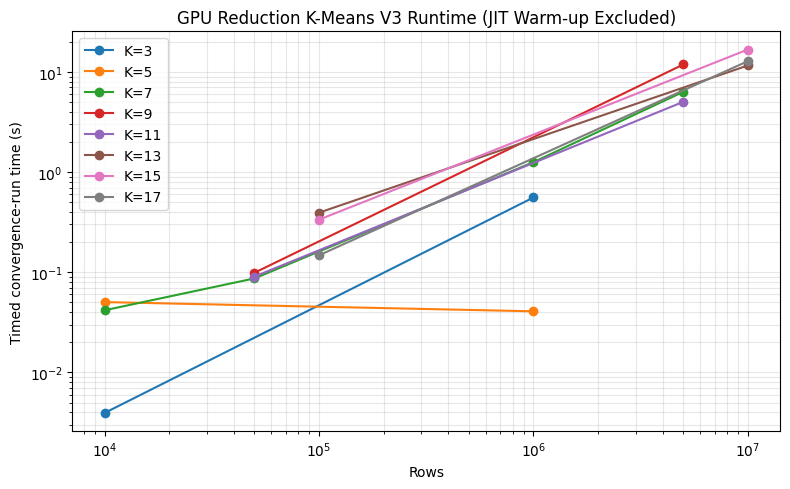

In [15]:

import matplotlib.pyplot as plt

if len(summary):
    plot_df = summary[
        summary["Implementation"]
        == "gpu_reduction_v3_aligned"
    ].copy()

    if len(plot_df):
        fig, ax = plt.subplots(
            figsize=(8, 5)
        )

        for k, group in plot_df.groupby(
            "K"
        ):
            group = group.sort_values(
                "Rows"
            )

            ax.plot(
                group["Rows"],
                group["Execution time"],
                marker="o",
                label=f"K={k}"
            )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Rows")
        ax.set_ylabel(
            "Timed convergence-run time (s)"
        )
        ax.set_title(
            "GPU Reduction K-Means V3 Runtime "
            "(JIT Warm-up Excluded)"
        )
        ax.grid(
            True,
            which="both",
            alpha=0.3
        )
        ax.legend()

        fig.tight_layout()

        plot_path = (
            OUT_DIR
            / "reduction_v3_total_runtime.png"
        )

        fig.savefig(
            plot_path,
            dpi=150
        )

        print(
            "Saved plot:",
            plot_path
        )

        plt.show()



## Files produced for each dataset

For a dataset such as:

```text
synthetic_data_10000_rows_10_cols_3_clusters.csv
```

the output is:

```text
results_gpu_atomic/
├── environment.json
├── summary.csv
├── initial_centroids_synthetic_data_10000_rows_10_cols_3_clusters.csv
├── final_results_synthetic_data_10000_rows_10_cols_3_clusters.csv
├── assignments/
│   └── assignments_synthetic_data_10000_rows_10_cols_3_clusters.csv
└── centroids/
    └── final_centroids_synthetic_data_10000_rows_10_cols_3_clusters.csv
```

### Assignment output

```text
ID, cluster, distance [, true_label]
```

### Final result output

Includes:

- execution time,
- iterations,
- time per iteration,
- convergence status,
- final maximum centroid movement,
- WCSS,
- cluster sizes,
- final centroid coordinates.

### Important fairness rule

For the final CPU-vs-Atomic-vs-Reduction tables, all implementations should use:

- the same feature columns,
- the same K,
- the same initial centroids,
- the same tolerance,
- the same maximum iteration count,
- and clearly documented timing boundaries.



## Batch notes

With:

```python
RUN_MODE = "all"
RUN_SIZES = None
```

the notebook automatically processes all discovered `rows<number>` folders, including:

```text
rows10000
rows50000
rows100000
rows1000000
rows5000000
rows10000000
```

and any future folder following the same naming convention.

Because `SKIP_COMPLETED = True`, rerunning after interruption skips datasets that already have `final_results_<dataset>.csv`.

For a partial test before the full run, use:

```python
RUN_SIZES = [10_000, 50_000, 100_000]
```



## Final convergence interpretation

The final assignment-stability rule is:

\[
\frac{\text{changed assignments}}{N}
\le 10^{-4}
\]

for **3 consecutive iterations**.

In percentage terms:

\[
10^{-4}\times100 = 0.01\%
\]

So at most 0.01% of points may change clusters during each of the final three iterations.

The four V2 diagnostic histories showed that this criterion is reachable even when exact zero assignment changes is not:

- 1M / K=3 reaches three consecutive qualifying iterations by about iteration 78.
- 5M / K=9 reaches them by about iteration 372.
- 10M / K=17 reaches them by about iteration 183.
- 10K / K=3 already meets the stricter centroid-movement tolerance at iteration 2.

For the final CPU-vs-Atomic-vs-Reduction comparison, use the **same convergence rule and initial centroids in every implementation**.
